# Predicting Agricultural Commodity Prices in Indian Mandis using Machine Learning
### AIML (2304322T) | Activity 2 | TY B.Tech Computer Engineering | Semester V | A.Y. 2026-27
**Implementation, Performance Evaluation and Comparative Analysis of ML Models (Regression)**

| Member | Name | Roll No. | PRN |
|---|---|---|---|
| 1 | Sakshi Shewale | 31 | 202401040126 |
| 2 | Samarth Kadam | 33 | 202401040131 |
| 3 | Tushar Kaldate | 47 | 202401040191 |

---
## Problem Statement
Farmers and traders sell crops in government-regulated markets (**mandis / APMC**). The price of a commodity (per quintal) changes with the **crop, variety, quality grade, market location and date**.
**Goal:** build a *regression* model that predicts the **Modal Price** (the most common selling price) of a commodity, and compare a proposed **ensemble model (Random Forest)** against Linear Regression, Decision Tree, KNN, SVM and MLP.

## Workflow followed 
1. Statistical summary  →  2. Data exploration & visualisation  →  3. Data preparation  →  4. Data splitting & cross-validation  →  5. Model implementation  →  6. Optimisation (hyper-parameter tuning)  →  7. Testing & performance evaluation  →  8. Comparative analysis & conclusion

## Step 0: Import libraries

In [1]:
import warnings, time, os
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 4.5)
RANDOM_STATE = 42      # fixed seed so results are reproducible
print('Libraries imported successfully')

Libraries imported successfully


## Step 1: Load the dataset and statistical summary
**Dataset:** daily mandi prices of agricultural commodities across India (source: Agmarknet / data.gov.in style data).
Each row = one commodity sold in one market on one day.

| Column | Meaning |
|---|---|
| State, District, Market | Where it was sold |
| Commodity, Variety, Grade | What was sold and its quality |
| Arrival_Date | Date of sale |
| Min_Price, Max_Price | Lowest / highest price that day (Rs per quintal) |
| **Modal_Price** | **Most common price that day (Rs per quintal) = our TARGET** |

In [2]:
# Works on your laptop (file next to the notebook), on Colab (after upload) or in the uploads folder
for path in ['commodity_prices.csv', '/content/commodity_prices.csv', '/mnt/user-data/uploads/commodity_prices.csv']:
    if os.path.exists(path):
        df = pd.read_csv(path, parse_dates=['Arrival_Date'])
        print('Loaded from:', path)
        break
else:
    raise FileNotFoundError('Place commodity_prices.csv in the same folder as this notebook')

print('Rows, Columns :', df.shape)
df.head()

Loaded from: commodity_prices.csv
Rows, Columns : (593539, 11)


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
0,Andhra Pradesh,Anantapur,Anantapur APMC,Mousambi (Sweet Lime),Mousambi,Medium,2025-12-30,800.0,1700.0,1200.0,77
1,Tamil Nadu,Pudukkottai,Alangudi (Uzhavar Sandhai ) APMC,Bottle gourd,Bottle Gourd,Local,2025-12-30,2500.0,3000.0,2750.0,82
2,Tamil Nadu,Thiruchirappalli,Manachanallur (Uzhavar Sandhai ) APMC,Snakeguard,Snakeguard,Local,2025-12-30,4600.0,4600.0,4600.0,156
3,Tamil Nadu,Perambalur,Perambalur (Uzhavar Sandhai ) APMC,Thondekai,Thondekai,Local,2025-12-30,6800.0,6800.0,6800.0,162
4,Tamil Nadu,Thiruchirappalli,Manachanallur (Uzhavar Sandhai ) APMC,Guava,Guava Alahabad,Local,2025-12-30,6000.0,6000.0,6000.0,185


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 593539 entries, 0 to 593538
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   State           593539 non-null  str           
 1   District        593539 non-null  str           
 2   Market          593539 non-null  str           
 3   Commodity       593539 non-null  str           
 4   Variety         593539 non-null  str           
 5   Grade           593539 non-null  str           
 6   Arrival_Date    593539 non-null  datetime64[us]
 7   Min_Price       593539 non-null  float64       
 8   Max_Price       593539 non-null  float64       
 9   Modal_Price     593539 non-null  float64       
 10  Commodity_Code  593539 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(1), str(6)
memory usage: 49.8 MB


In [4]:
# Statistical summary of numeric columns
df[['Min_Price', 'Max_Price', 'Modal_Price']].describe().round(1)

,Min_Price,Max_Price,Modal_Price
count,593539.0,593539.0,593539.0
mean,4102.9,4840.3,4494.2
std,6181.3,7359.5,6655.4
min,0.0,0.5,0.5
25%,2000.0,2373.0,2200.0
50%,3000.0,3600.0,3500.0
75%,5000.0,5590.0,5251.0
max,980083.0,980083.0,980083.0


In [5]:
# Missing values, duplicates, number of unique values and date range
print('Missing values per column:\n', df.isna().sum().to_string())
print('\nDuplicate rows       :', df.duplicated().sum())
print('Date range           :', df.Arrival_Date.min().date(), 'to', df.Arrival_Date.max().date())
print('\nUnique values -> States:', df.State.nunique(), '| Districts:', df.District.nunique(),
      '| Markets:', df.Market.nunique(), '| Commodities:', df.Commodity.nunique(),
      '| Varieties:', df.Variety.nunique(), '| Grades:', df.Grade.nunique())

Missing values per column:
 State             0
District          0
Market            0
Commodity         0
Variety           0
Grade             0
Arrival_Date      0
Min_Price         0
Max_Price         0
Modal_Price       0
Commodity_Code    0



Duplicate rows       : 0
Date range           : 2025-12-30 to 2026-04-21

Unique values -> States: 30 | Districts: 542 | Markets: 3056 | Commodities: 316 | Varieties: 772 | Grades: 16


**Observations**
- ~5.9 lakh rows, **no missing values**, no duplicates.
- Prices are **highly skewed**: the median is about Rs 3,500 but the maximum is Rs 9.8 lakh (an error/extreme value).
- Some rows are logically wrong (Modal price outside the Min-Max range). We clean these in Step 3.

## Step 2: Data exploration and visualisation (EDA)
We look at the data *before* cleaning, to understand which problems exist.

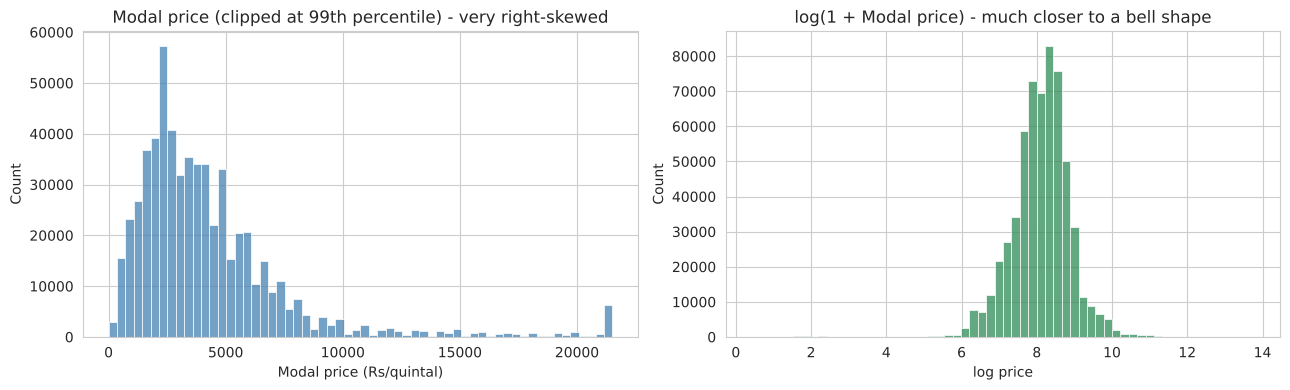

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df.Modal_Price.clip(upper=df.Modal_Price.quantile(0.99)), bins=60, ax=ax[0], color='steelblue')
ax[0].set_title('Modal price (clipped at 99th percentile) - very right-skewed')
ax[0].set_xlabel('Modal price (Rs/quintal)')
sns.histplot(np.log1p(df.Modal_Price), bins=60, ax=ax[1], color='seagreen')
ax[1].set_title('log(1 + Modal price) - much closer to a bell shape')
ax[1].set_xlabel('log price')
plt.tight_layout(); plt.show()

**Why this matters:** very skewed targets confuse many models. Taking the **log of the price** makes the distribution balanced, so we will train models on the log price and convert predictions back to rupees.

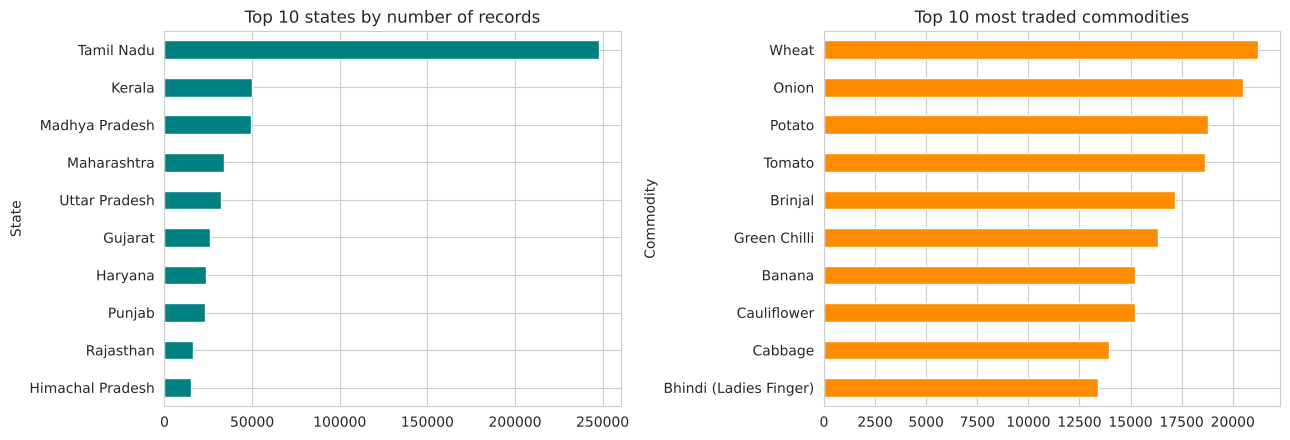

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
df.State.value_counts().head(10).sort_values().plot(kind='barh', ax=ax[0], color='teal')
ax[0].set_title('Top 10 states by number of records')
df.Commodity.str.title().value_counts().head(10).sort_values().plot(kind='barh', ax=ax[1], color='darkorange')
ax[1].set_title('Top 10 most traded commodities')
plt.tight_layout(); plt.show()

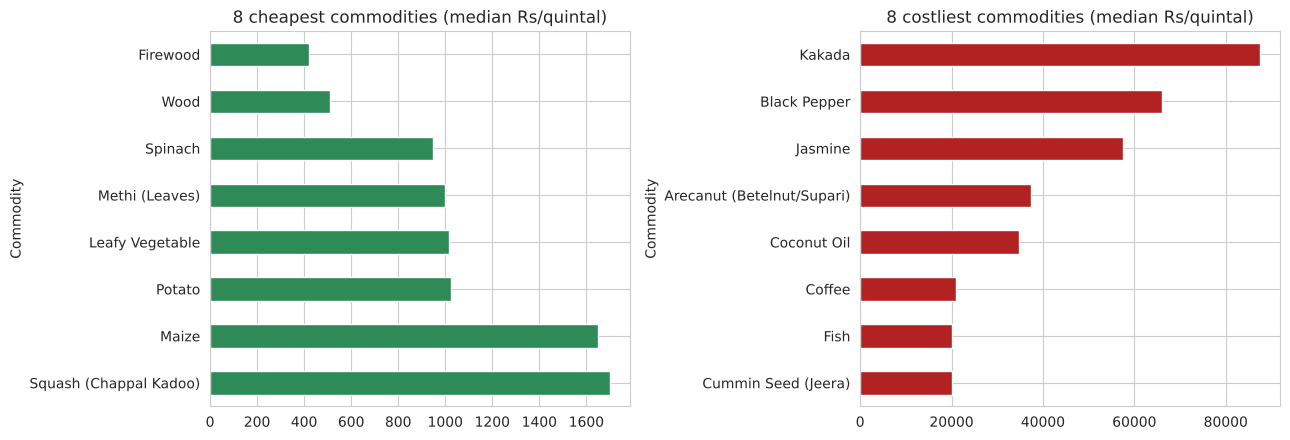

In [8]:
# Which commodities are cheapest / most expensive (median price)?
med = df.assign(Commodity=df.Commodity.str.title()).groupby('Commodity').Modal_Price.agg(['median', 'count'])
med = med[med['count'] >= 100]                      # ignore rarely traded items
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
med['median'].nsmallest(8).sort_values(ascending=False).plot(kind='barh', ax=ax[0], color='seagreen')
ax[0].set_title('8 cheapest commodities (median Rs/quintal)')
med['median'].nlargest(8).sort_values().plot(kind='barh', ax=ax[1], color='firebrick')
ax[1].set_title('8 costliest commodities (median Rs/quintal)')
plt.tight_layout(); plt.show()

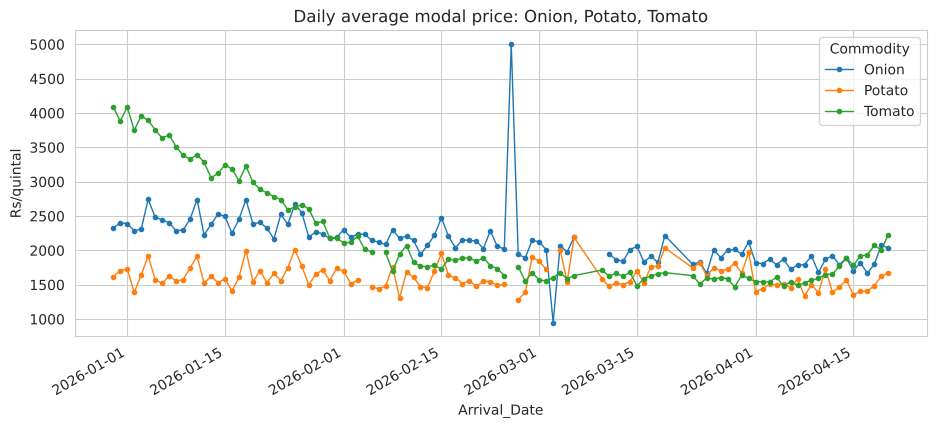

In [9]:
# Price trend over time for 3 everyday vegetables (daily national average)
trend = (df[df.Commodity.isin(['Onion', 'Potato', 'Tomato'])]
         .groupby(['Arrival_Date', 'Commodity']).Modal_Price.mean().unstack())
trend.plot(figsize=(11, 4.5), marker='.', linewidth=1)
plt.title('Daily average modal price: Onion, Potato, Tomato'); plt.ylabel('Rs/quintal'); plt.show()

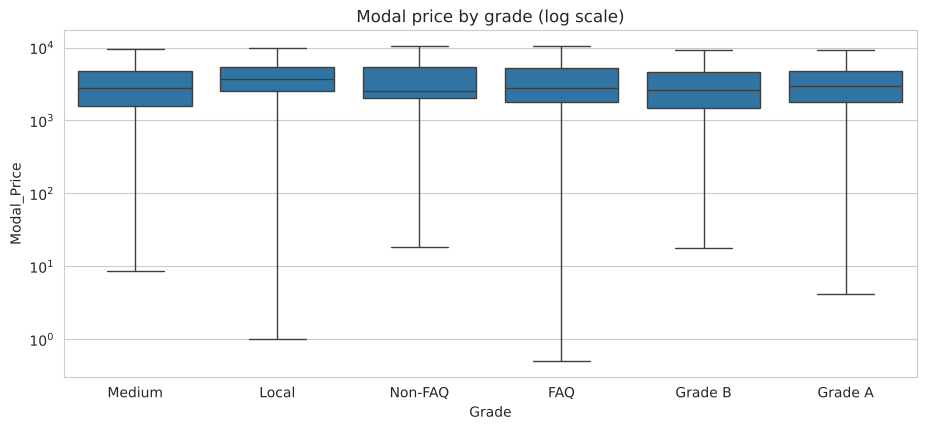

In [10]:
# Price spread by quality grade (top 6 grades, log scale so boxes are readable)
top_grades = df.Grade.value_counts().head(6).index
plt.figure(figsize=(11, 4.5))
sns.boxplot(data=df[df.Grade.isin(top_grades)], x='Grade', y='Modal_Price', showfliers=False)
plt.yscale('log'); plt.title('Modal price by grade (log scale)'); plt.show()

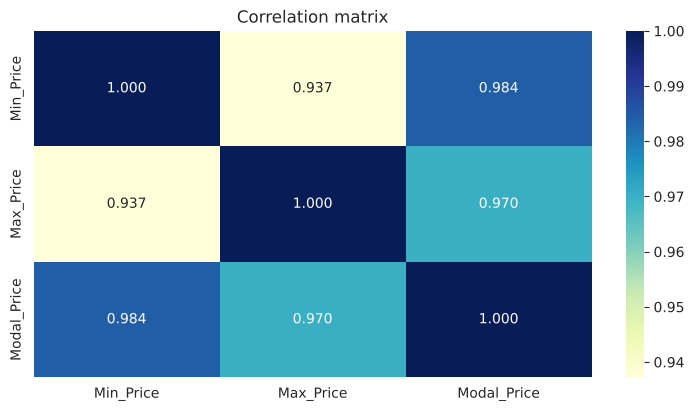

In [11]:
# Correlation between Min, Max and Modal price
sns.heatmap(df[['Min_Price', 'Max_Price', 'Modal_Price']].corr(), annot=True, cmap='YlGnBu', fmt='.3f')
plt.title('Correlation matrix'); plt.show()

**Key insight:** Min, Max and Modal prices are almost perfectly correlated (>0.98). If we used Min and Max to predict Modal, the task would be *too easy* and not useful (this is called **data leakage**: on a real day you would not know Min/Max before the price is formed).
**Decision:** we predict Modal price **only from "context" features**: State, District, Commodity, Variety, Grade and date. We prove the leakage point with an experiment in Step 8.

## Step 3: Data preparation
**3.1 Cleaning**  (every step is simple and explainable)
1. Standardise commodity names (`tulip` and `Tulip` are the same item).
2. Remove duplicate rows.
3. Remove logically wrong rows: Modal price must lie between Min and Max, and prices must be positive.
4. Remove extreme outliers: prices above Rs 30,000/quintal (top ~0.5%: cardamom, dry fruits, flowers, typing errors). The model focuses on everyday farm produce.

In [12]:
before = len(df)
data = df.copy()
data['Commodity'] = data['Commodity'].str.strip().str.title()      # 1. unify names
data = data.drop_duplicates()                                       # 2. duplicates
data = data[(data.Modal_Price > 0) &                                # 3. logical errors
            (data.Modal_Price >= data.Min_Price) &
            (data.Modal_Price <= data.Max_Price)]
data = data[data.Modal_Price <= 30000]                              # 4. extreme outliers
print(f'Rows before: {before:,} | after cleaning: {len(data):,} | removed: {before-len(data):,} ({(before-len(data))/before:.2%})')

Rows before: 593,539 | after cleaning: 590,570 | removed: 2,969 (0.50%)


**3.2 Feature engineering** - the date is converted into simple numbers (month, day of month, day of week).
**3.3 Sampling** - 5.9 lakh rows is too heavy for slower models such as SVM and KNN on a laptop, so we take a **random sample of 20,000 rows** and use the *same* sample for *all* models (fair comparison).

In [13]:
data['Month'] = data.Arrival_Date.dt.month
data['Day'] = data.Arrival_Date.dt.day
data['DayOfWeek'] = data.Arrival_Date.dt.dayofweek

sample = data.sample(n=20000, random_state=RANDOM_STATE)

cat_features = ['State', 'District', 'Commodity', 'Variety', 'Grade']
num_features = ['Month', 'Day', 'DayOfWeek']
X = sample[cat_features + num_features]
y = sample['Modal_Price']

print('Sample size:', X.shape)
X.head()

Sample size: (20000, 8)


,State,District,Commodity,Variety,Grade,Month,Day,DayOfWeek
474115,Tamil Nadu,Erode,Onion Green,Onion Green,Local,3,31,1
478370,Tamil Nadu,Thiruvannamalai,Bhindi (Ladies Finger),Bhindi,Local,4,1,2
241667,Madhya Pradesh,Chhindwara,Maize,Local,Non-FAQ,2,8,6
395100,Tamil Nadu,Ramanathapuram,Tomato,Deshi,Local,3,14,5
331281,Punjab,Patiala,Raddish,Other,Grade C,2,23,0


**3.4 Encoding and scaling (one preprocessing block used by every model)**
- Text columns -> **One-Hot Encoding** (each category becomes a 0/1 column). Very rare categories (<20 rows) are grouped together.
- Number columns -> **StandardScaler** (needed by KNN, SVM, MLP, which are distance-based).
- Target -> **log transform** (`TransformedTargetRegressor`): the model learns on log-price, and its predictions are automatically converted back to rupees, so every metric below is in **Rs/quintal**.

In [14]:
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist'), cat_features),
    ('num', StandardScaler(), num_features)
])

def make_model(estimator):
    # preprocessing -> model, with log-transformed target. One reusable recipe for all models.
    pipe = Pipeline([('prep', preprocessor), ('model', estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

## Step 4: Data splitting and cross-validation
- **Train / Test split = 80 / 20.** The test set is locked away and used only once at the end.
- **5-fold cross-validation** on the training set: the training data is cut into 5 parts; each part takes a turn as validation. This gives a more trustworthy score than a single split and shows how *stable* a model is.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print('Training rows:', len(X_train), '| Testing rows:', len(X_test))
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training rows: 16000 | Testing rows: 4000


## Step 5: Model implementation
### Proposed model: **Random Forest Regressor** (Ensemble learning)
A Random Forest builds *many* decision trees on random parts of the data and **averages** their answers.
Averaging many different trees cancels individual mistakes -> lower variance, less over-fitting than one tree. It also handles mixed categorical features well and needs little tuning.

### Models used for comparison (as asked in the activity sheet)
| Model | One-line idea |
|---|---|
| Linear Regression | Baseline: fits one straight-line formula |
| Decision Tree | One tree of yes/no questions; easy to read but over-fits |
| KNN | Predicts the average of the K most similar past records |
| SVM (SVR) | Fits a smooth curve inside a margin of tolerance |
| MLP | Small neural network |
| **Random Forest** | **Many trees, averaged (our ensemble)** |

In [16]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree'    : DecisionTreeRegressor(random_state=RANDOM_STATE),
    'KNN'              : KNeighborsRegressor(n_neighbors=5),
    'SVM (SVR)'        : SVR(kernel='rbf', C=3),
    'MLP'              : MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True, random_state=RANDOM_STATE),
    'Random Forest'    : RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE),
}

# 5-fold cross-validation R2 on the TRAINING data only
cv_rows = []
for name, est in models.items():
    t = time.time()
    scores = cross_val_score(make_model(est), X_train, y_train, cv=kfold, scoring='r2')
    cv_rows.append({'Model': name, 'CV R2 (mean)': scores.mean(), 'CV R2 (std)': scores.std(), 'Time (s)': time.time() - t})
    print(f'{name:18s} CV R2 = {scores.mean():.3f} +/- {scores.std():.3f}   ({time.time()-t:.0f}s)')
cv_df = pd.DataFrame(cv_rows).set_index('Model').round(3)

Linear Regression  CV R2 = 0.583 +/- 0.025   (1s)


Decision Tree      CV R2 = 0.522 +/- 0.084   (2s)


KNN                CV R2 = 0.502 +/- 0.010   (2s)


SVM (SVR)          CV R2 = 0.692 +/- 0.022   (144s)


MLP                CV R2 = 0.624 +/- 0.017   (14s)


Random Forest      CV R2 = 0.712 +/- 0.021   (132s)


In [17]:
cv_df.sort_values('CV R2 (mean)', ascending=False)

,CV R2 (mean),CV R2 (std),Time (s)
Model,,,
Random Forest,0.712,0.021,132.272
SVM (SVR),0.692,0.022,143.644
MLP,0.624,0.017,14.051
Linear Regression,0.583,0.025,0.537
Decision Tree,0.522,0.084,2.036
KNN,0.502,0.010,2.481


**Reading the table:** a higher CV R2 is better; a small `std` means the model is stable on different parts of the data. Random Forest already leads, so it is our candidate for tuning.

## Step 6: Optimisation (hyper-parameter tuning of Random Forest)
Hyper-parameters are settings we choose *before* training (number of trees, tree depth...). We use **Randomized Search with 3-fold CV** to try several combinations and keep the best one.
- `n_estimators`: number of trees
- `max_depth`: how deep each tree may grow (limits over-fitting)
- `min_samples_leaf`: minimum records in a leaf (smoother predictions)
- `max_features`: share of features each split may look at (adds diversity between trees)

In [18]:
param_grid = {
    'regressor__model__n_estimators'    : [100, 200],
    'regressor__model__max_depth'       : [None, 20, 40],
    'regressor__model__min_samples_leaf': [1, 2, 4],
    'regressor__model__max_features'    : [0.3, 0.6, 1.0],
}
search = RandomizedSearchCV(make_model(RandomForestRegressor(random_state=RANDOM_STATE)),
                            param_distributions=param_grid, n_iter=6, cv=3,
                            scoring='r2', random_state=RANDOM_STATE, n_jobs=1)
t = time.time()
search.fit(X_train, y_train)
print(f'Tuning finished in {time.time()-t:.0f}s')
print('Best CV R2     :', round(search.best_score_, 3))
print('Best parameters:', {k.split("__")[-1]: v for k, v in search.best_params_.items()})

Tuning finished in 276s
Best CV R2     : 0.66
Best parameters: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}


In [19]:
res = pd.DataFrame(search.cv_results_)
res['params'] = res['params'].apply(lambda p: {k.split('__')[-1]: v for k, v in p.items()})
res[['params', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score').round(3)

,params,mean_test_score,rank_test_score
3,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",0.660,1
2,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",0.615,2
1,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.614,3
4,"{'n_estimators': 100, 'min_samples_leaf': 2, '...",0.606,4
5,"{'n_estimators': 200, 'min_samples_leaf': 4, '...",0.604,5
0,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.507,6


**Finding from tuning:** the best combination uses **fully grown trees** (no depth limit, `min_samples_leaf=1`, all features per split, 100 trees), which is the same as the library default. Every *restricted* version (shallower trees, bigger leaves, fewer features) scored lower. Reason: prices depend on very specific combinations (e.g. *this* commodity in *this* district), so the trees need fine detail. More trees (200) did not help either, so 100 trees is enough.
So tuning *confirmed* that Random Forest was already well configured (a valid result - tuning does not always change the settings). The CV score here (3-fold, less training data per fold) is lower than the 5-fold score above; compare only numbers computed the same way.

## Step 7: Testing and performance evaluation (on the unseen 20% test set)
**Regression metrics used (all in rupees per quintal except R2)**
- **MSE** - average of squared errors (loss function; punishes large mistakes heavily)
- **RMSE** - square root of MSE, in rupees (typical size of an error, sensitive to big mistakes)
- **MAE** - average absolute error in rupees (easiest to explain: "on average we are off by Rs X")
- **R2 Score** - share of price variation explained by the model (1 = perfect, 0 = no better than guessing the average)

In [20]:
best_rf = search.best_estimator_
final_models = {name: make_model(est) for name, est in models.items() if name != 'Random Forest'}
final_models['Random Forest (Tuned)'] = best_rf

rows, preds = [], {}
for name, model in final_models.items():
    if name != 'Random Forest (Tuned)':
        model.fit(X_train, y_train)                    # tuned RF is already trained by the search
    p_test, p_train = model.predict(X_test), model.predict(X_train)
    preds[name] = p_test
    mse = mean_squared_error(y_test, p_test)
    rows.append({'Model': name, 'MSE': mse, 'RMSE': np.sqrt(mse),
                 'MAE': mean_absolute_error(y_test, p_test),
                 'Test R2': r2_score(y_test, p_test), 'Train R2': r2_score(y_train, p_train)})
results = pd.DataFrame(rows).set_index('Model').sort_values('Test R2', ascending=False)
results['Overfit gap (Train-Test R2)'] = results['Train R2'] - results['Test R2']
results.round(3)

,MSE,RMSE,MAE,Test R2,Train R2,Overfit gap (Train-Test R2)
Model,,,,,,
Random Forest (Tuned),2789109.697,1670.063,868.960,0.764,0.952,0.188
SVM (SVR),3065201.331,1750.772,933.814,0.741,0.905,0.164
MLP,3993909.852,1998.477,1072.011,0.662,0.778,0.115
Linear Regression,4377440.770,2092.233,1139.782,0.630,0.640,0.010
Decision Tree,4732339.853,2175.394,1095.296,0.600,0.998,0.398
KNN,5235456.419,2288.112,1240.376,0.558,0.667,0.109


**Train R2 vs Test R2 (Bias-Variance check):**
- Train R2 *much higher* than Test R2 -> the model memorised the training data (**high variance / over-fitting**) - typical for a single Decision Tree and KNN.
- Both R2 low -> model is too simple (**high bias / under-fitting**) - typical for Linear Regression.
- Random Forest still fits the training data closely (Train R2 about 0.95) but generalises best (highest Test R2); its gap is far smaller than a single Decision Tree's (about 0.40), because averaging many trees reduces variance.

## Step 8: Comparative result analysis (charts)

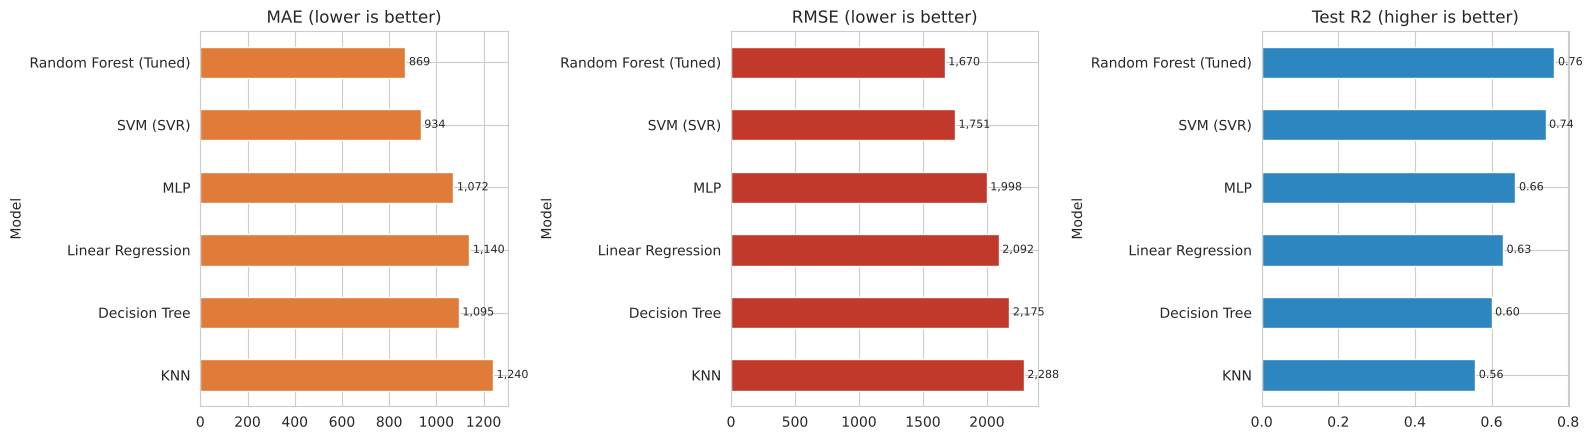

In [21]:
order = results.sort_values('Test R2').index
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric, color in zip(ax, ['MAE', 'RMSE', 'Test R2'], ['#e07b39', '#c0392b', '#2e86c1']):
    results.loc[order, metric].plot(kind='barh', ax=a, color=color)
    a.set_title(metric + (' (lower is better)' if metric != 'Test R2' else ' (higher is better)'))
    for i, v in enumerate(results.loc[order, metric]):
        a.text(v, i, f' {v:.2f}' if metric == 'Test R2' else f' {v:,.0f}', va='center', fontsize=8)
plt.tight_layout(); plt.show()

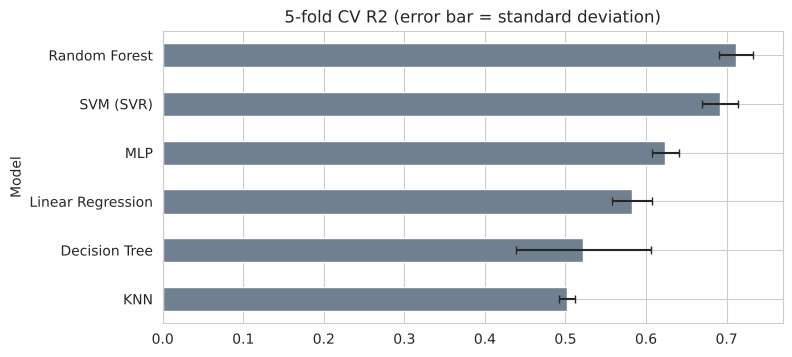

In [22]:
# Cross-validation stability: mean +/- std of R2
cv_df['CV R2 (mean)'].sort_values().plot(kind='barh', xerr=cv_df.loc[cv_df['CV R2 (mean)'].sort_values().index, 'CV R2 (std)'],
                                         color='slategray', figsize=(8, 3.8), capsize=3)
plt.title('5-fold CV R2 (error bar = standard deviation)'); plt.show()

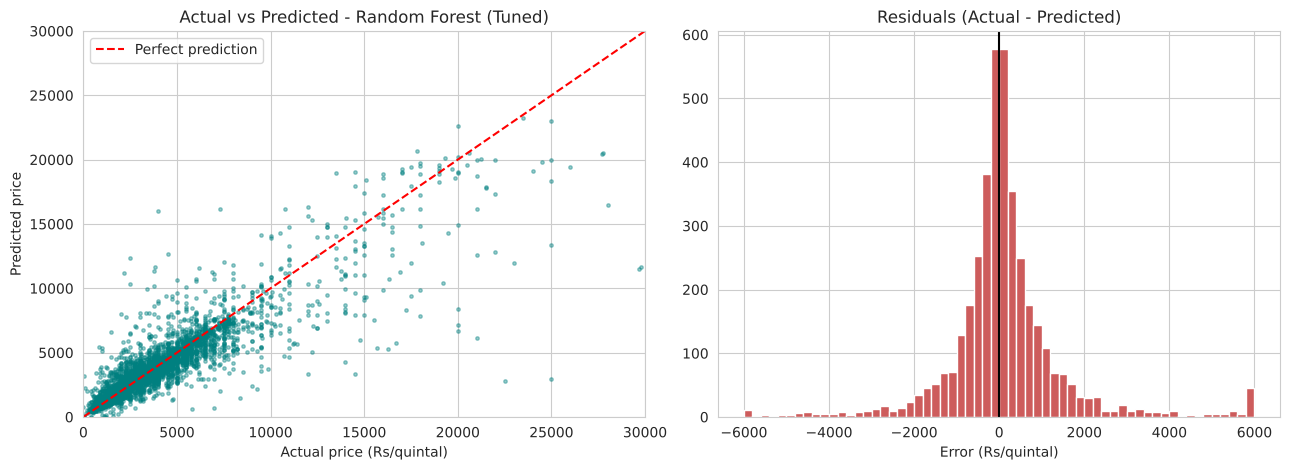

In [23]:
# Best model: actual vs predicted, and residuals
best_name = 'Random Forest (Tuned)'
p = preds[best_name]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].scatter(y_test, p, s=6, alpha=0.4, color='teal')
lim = [0, 30000]
ax[0].plot(lim, lim, 'r--', label='Perfect prediction'); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel('Actual price (Rs/quintal)'); ax[0].set_ylabel('Predicted price'); ax[0].set_title('Actual vs Predicted - ' + best_name); ax[0].legend()
resid = y_test - p
ax[1].hist(resid.clip(-6000, 6000), bins=60, color='indianred')
ax[1].axvline(0, color='k'); ax[1].set_title('Residuals (Actual - Predicted)'); ax[1].set_xlabel('Error (Rs/quintal)')
plt.tight_layout(); plt.show()

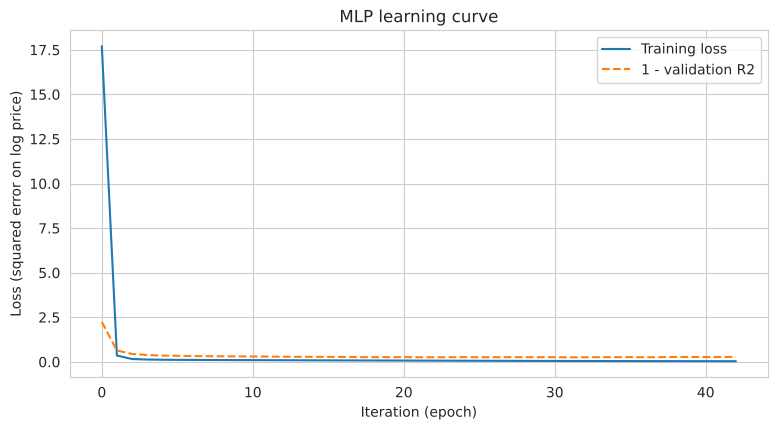

In [24]:
# MLP training loss curve (the 'Loss' asked in the activity sheet)
mlp_net = final_models['MLP'].regressor_.named_steps['model']
plt.plot(mlp_net.loss_curve_, label='Training loss')
plt.plot(1 - np.array(mlp_net.validation_scores_), label='1 - validation R2', linestyle='--')
plt.xlabel('Iteration (epoch)'); plt.ylabel('Loss (squared error on log price)'); plt.title('MLP learning curve'); plt.legend(); plt.show()

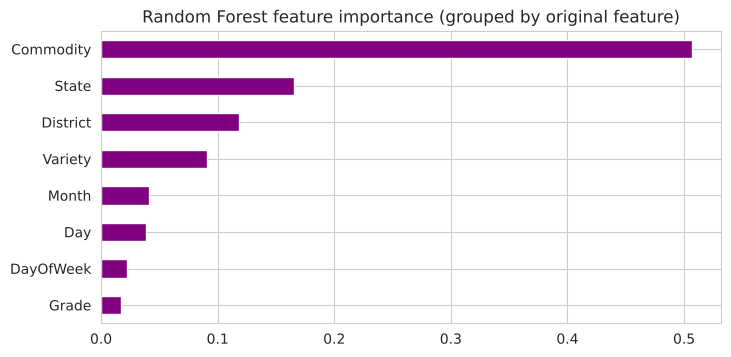

Commodity    50.6 %
State        16.6 %
District     11.8 %
Variety       9.1 %
Month         4.1 %
Day           3.8 %
DayOfWeek     2.2 %
Grade         1.7 %
dtype: str


In [25]:
# Which inputs matter most? Add up the importance of all one-hot columns of the same original feature
rf_pipe = best_rf.regressor_
names = rf_pipe.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps['model'].feature_importances_, index=names)
group = imp.groupby(lambda n: n.split('__')[1].split('_')[0] if n.startswith('cat') else n.split('__')[1]).sum()
group.sort_values().plot(kind='barh', color='purple', figsize=(8, 3.8))
plt.title('Random Forest feature importance (grouped by original feature)'); plt.show()
print((group.sort_values(ascending=False) * 100).round(1).astype(str) + ' %')

In [26]:
# Where does the model do well / badly? MAE and % error for the 10 most common commodities in the test set
test_df = X_test.copy(); test_df['Actual'] = y_test; test_df['Pred'] = p
test_df['AbsErr'] = (test_df.Actual - test_df.Pred).abs()
test_df['PctErr'] = test_df.AbsErr / test_df.Actual * 100
top10 = test_df.Commodity.value_counts().head(10).index
(test_df[test_df.Commodity.isin(top10)].groupby('Commodity')
    .agg(Records=('Actual', 'size'), Avg_Actual=('Actual', 'mean'), MAE=('AbsErr', 'mean'), Avg_pct_error=('PctErr', 'mean'))
    .round(1).sort_values('Records', ascending=False))

,Records,Avg_Actual,MAE,Avg_pct_error
Commodity,,,,
Potato,136,1492.1,266.0,22.7
Wheat,133,2430.9,115.6,4.4
Onion,122,2018.6,354.3,20.1
Tomato,120,2285.6,498.5,23.8
Cauliflower,118,2140.8,606.9,36.5
Green Chilli,115,4917.1,1134.1,27.8
Cabbage,111,1858.9,392.3,25.1
Bhindi (Ladies Finger),110,4262.7,775.4,22.2
Bottle Gourd,105,1964.9,378.3,23.4


### Data-leakage experiment (why we removed Min and Max price)
Same tuned Random Forest, but now we *also* give it Min_Price and Max_Price.

In [27]:
leak_X = sample[cat_features + num_features + ['Min_Price', 'Max_Price']]
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(leak_X, y, test_size=0.20, random_state=RANDOM_STATE)
leak_prep = ColumnTransformer([
    ('cat', OneHotEncoder(min_frequency=20, handle_unknown='infrequent_if_exist'), cat_features),
    ('num', StandardScaler(), num_features + ['Min_Price', 'Max_Price'])])
leak_model = TransformedTargetRegressor(
    regressor=Pipeline([('prep', leak_prep), ('model', RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE))]),
    func=np.log1p, inverse_func=np.expm1).fit(Xl_tr, yl_tr)
pl = leak_model.predict(Xl_te)
print(f'WITH Min/Max price  -> R2 = {r2_score(yl_te, pl):.3f}, MAE = Rs {mean_absolute_error(yl_te, pl):,.0f}  (looks great, but unrealistic)')
print(f'WITHOUT Min/Max     -> R2 = {r2_score(y_test, p):.3f}, MAE = Rs {mean_absolute_error(y_test, p):,.0f}  (honest, useful model)')

WITH Min/Max price  -> R2 = 0.995, MAE = Rs 63  (looks great, but unrealistic)
WITHOUT Min/Max     -> R2 = 0.764, MAE = Rs 869  (honest, useful model)


## Step 9: Demonstration - predict the price of a new record
A small function that takes simple inputs (like a farmer or trader would know) and returns the predicted modal price.

In [28]:
def predict_price(state, district, commodity, variety, grade, date):
    d = pd.to_datetime(date)
    row = pd.DataFrame([{'State': state, 'District': district, 'Commodity': commodity, 'Variety': variety,
                         'Grade': grade, 'Month': d.month, 'Day': d.day, 'DayOfWeek': d.dayofweek}])
    return float(best_rf.predict(row)[0])

# pick 5 real examples from the test set and compare
demo = X_test.head(5).copy(); demo['Actual'] = y_test.head(5).values
demo['Predicted'] = best_rf.predict(X_test.head(5)).round(0)
demo[['State', 'Commodity', 'Variety', 'Grade', 'Actual', 'Predicted']]

,State,Commodity,Variety,Grade,Actual,Predicted
147012,Tamil Nadu,Green Avare (W),Avare (W),Local,5000.0,4945.0
150002,Pondicherry,Paddy (Common),B P T,Non-FAQ,2243.0,1991.0
417351,Tamil Nadu,Bottle Gourd,Bottle Gourd,Local,1000.0,1209.0
532390,Tamil Nadu,Beans,Beans (Whole),Local,7500.0,6721.0
532794,Madhya Pradesh,Bengal Gram (Gram)(Whole),Gram,FAQ,5250.0,5226.0


In [29]:
# Try your own input!
price = predict_price('Maharashtra', 'Pune', 'Onion', 'Onion', 'FAQ', '2026-03-15')
print(f'Predicted modal price of Onion (FAQ) in Pune on 15-Mar-2026: Rs {price:,.0f} per quintal  (about Rs {price/100:,.1f} per kg)')

Predicted modal price of Onion (FAQ) in Pune on 15-Mar-2026: Rs 1,204 per quintal  (about Rs 12.0 per kg)


## Step 10: Final comparison table and conclusion

In [30]:
final = results[['MAE', 'RMSE', 'MSE', 'Test R2', 'Train R2']].copy()
final['CV R2 (5-fold)'] = [cv_df['CV R2 (mean)'].get(n.replace(' (Tuned)', ''), np.nan) for n in final.index]
final['Rank'] = final['Test R2'].rank(ascending=False).astype(int)
final.round(3)

,MAE,RMSE,MSE,Test R2,Train R2,CV R2 (5-fold),Rank
Model,,,,,,,
Random Forest (Tuned),868.960,1670.063,2789109.697,0.764,0.952,0.712,1
SVM (SVR),933.814,1750.772,3065201.331,0.741,0.905,0.692,2
MLP,1072.011,1998.477,3993909.852,0.662,0.778,0.624,3
Linear Regression,1139.782,2092.233,4377440.770,0.630,0.640,0.583,4
Decision Tree,1095.296,2175.394,4732339.853,0.600,0.998,0.522,5
KNN,1240.376,2288.112,5235456.419,0.558,0.667,0.502,6


In [31]:
best = results['Test R2'].idxmax()
print(f"Best model on unseen data: {best}")
print(f"  R2   = {results.loc[best, 'Test R2']:.3f}  -> explains {results.loc[best, 'Test R2']*100:.0f}% of the price variation")
print(f"  MAE  = Rs {results.loc[best, 'MAE']:,.0f} per quintal  (about Rs {results.loc[best, 'MAE']/100:.1f} per kg)")
print(f"  RMSE = Rs {results.loc[best, 'RMSE']:,.0f} per quintal")

Best model on unseen data: Random Forest (Tuned)
  R2   = 0.764  -> explains 76% of the price variation
  MAE  = Rs 869 per quintal  (about Rs 8.7 per kg)
  RMSE = Rs 1,670 per quintal


### Conclusion
1. We built a regression system to predict **mandi modal prices** from commodity, variety, grade, location and date, and compared **six algorithms** with identical preprocessing, split and cross-validation.
2. The **Random Forest (ensemble)** gave the best accuracy and the most stable cross-validation scores; tuning confirmed that its settings were already close to the best. Single models were weaker: the Decision Tree over-fits, KNN suffers in high-dimensional one-hot data, Linear Regression under-fits, and SVM / MLP are slower or less accurate on this type of categorical data.
3. **Commodity type** is by far the most important factor (about half of the importance), followed by **location** (State + District, about 28%) and variety (about 9%). Date features together give about 10%; since the data covers only about four months, seasonal patterns cannot be learned.
4. Removing Min/Max price avoided **data leakage**. The honest model is less "perfect" but actually usable for price estimation.

### Limitations and ethical / societal considerations
- Only ~4 months of data (Dec 2025 - Apr 2026): seasonality and festivals cannot be learned. Predictions are estimates, not guarantees.
- Average percentage error is only about 4% for stable crops such as Wheat but 20-35% for fast-changing vegetables (Tomato, Cauliflower, Green Chilli), so the model is best seen as a **price guide**, not an exact forecast.
- Errors in rupees are larger for expensive commodities; a wrong estimate may mislead a small farmer or lead a trader to exploit an information gap. The tool should support, not replace, local market knowledge.
- Data coverage is uneven (Tamil Nadu has the most records), so predictions for states with few records are less reliable (fairness).
- Prices are public market data; no personal information is used.
